# 5 · ConcreteCrack：混凝土裂缝、FEM-FCT 和复现的边界

**这一篇学什么**

- 嵌在二维网格里的一维裂缝单元（`LineElements`，OGS `GEOMETRY_AREA`）
- 随孔隙率变化的渗透率（Kozeny–Carman）和扩散（`$DIFFUSION 8`）
- 对流占优输运的 FEM-FCT，以及 OGS 的符号约定
- **不能**复现的东西：病态水流问题里由 GEMS 舍入误差驱动的水头

## 问题

2.5 × 10.5 cm 的竖直 x–z 剖面（OGS5GEMDEV `PETSc/ConcreteCrack`，“decal”）：10 cm 混凝土，上面 5 mm 表层，
左边一条 0.5 mm 宽、5 cm 深的裂缝。顶部接触含硝酸根的溶液（水头 10.105 m），底部水头 10.0 m。基准只算 10 步 × 1 s——
检验的是初始化和裂缝–基质耦合，而不是真正的溶蚀。

| 量 | 值 | OGS 文件 |
|---|---|---|
| 网格 | 20 × 84 四边形 + 40 个线单元（裂缝） | `decal.msh` |
| 裂缝开度 | 0.5 mm（`GEOMETRY_AREA`） | `decal.mmp` |
| $K_0$ | 10⁻⁹（表层）、5·10⁻¹¹（混凝土）、0.41 m/s（裂缝）；Kozeny–Carman | `decal.mmp` |
| 扩散 | $D = 10^{-9}\,\phi^3/\phi_0^2$ × 曲折度（0.0383 / 1） | `decal.mcp`、`.mmp` |
| 弥散度 | 10⁻⁵ / 10⁻⁶ m | `decal.mmp` |
| 数值方法 | FEM-FCT，3×3 Gauss | `decal.num` |
| 初始化学 | 四个区：混凝土、裂缝、表层、顶边 | `decal.ic` |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.path import Path as MplPath

ROOT = next(p / 'GEMS_FEniCSx_OGS5_Template' for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'GEMS_FEniCSx_OGS5_Template').exists())
sys.path.insert(0, str(ROOT))
from ogs_io import read_msh, read_constant_blocks
from fe_mesh import OGSMesh
from flow import Darcy
from transport import Transport
from gems_ogs import OGSGEMS
from ogs_models import element_mean, harmonic_mean, porosity_diffusion_8, kozeny_carman_4, LineElements
from reactive_transport import run

CASE = ROOT / 'cases' / '5_concretecrack'
OGS = CASE / 'ogs_input'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

## 带裂缝的网格和四个初始区

四边形组成 dolfinx 网格。裂缝的 40 个线单元和二维网格共用 x = 0 上的节点；`LineElements` 把它们的贡献（所有积分乘开度）
组装成稀疏矩阵，加到二维矩阵上。它们的体积也计入多余水源项用的节点体积。

`decal.ic` 按区依次覆盖初始 b 向量：整个区域 → 裂缝节点 → 表层 → 顶边。

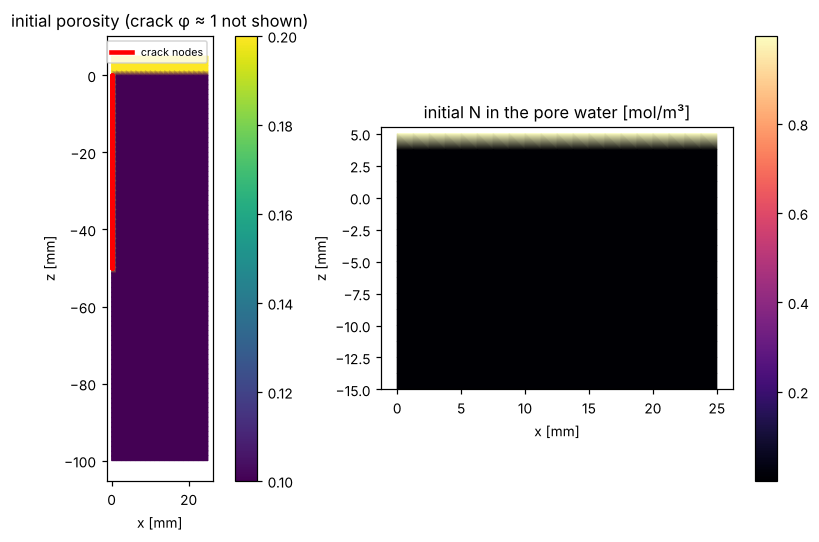

In [2]:
points, cells, mats, _ = read_msh(OGS / 'decal.msh')
xz = points[:, [0, 2]]
mesh = OGSMesh(xz, cells['quad'], 'quadrilateral')
mat = mats['quad']
crack = LineElements(mesh.n_nodes, xz, cells['line'], 0.5e-3)
node_volume = mesh.node_volume + crack.node_volume()

in_crack = (np.abs(xz[:, 0]) < 1e-6) & (xz[:, 1] >= -0.05 - 1e-6) & (xz[:, 1] <= 1e-4 + 1e-6)
top = MplPath(np.array([[0, .005], [0, .001], [.0005, 1e-4], [.025, .001], [.025, .005]]))
in_top = top.contains_points(xz, radius=1e-6) | top.contains_points(xz, radius=-1e-6)
upper = np.flatnonzero(np.isclose(xz[:, 1], 0.005))
lower = np.flatnonzero(np.isclose(xz[:, 1], -0.1))
zone = {'DOMAIN': np.ones(mesh.n_nodes, bool), 'SURF_1': in_crack, 'TOP': in_top, 'UPPER_BOUNDARY': np.isclose(xz[:, 1], 0.005)}

chem = OGSGEMS(CASE / 'gems' / 'cement_bc-dat.lst', mesh.n_nodes, hydrology='full', min_porosity=1e-6, boundary_nodes=upper)
comps = [f'{i + 1}-{e}' for i, e in enumerate(chem.elements)]
b_init = np.zeros((mesh.n_nodes, chem.nIC))
for pcs, var, geo, val in read_constant_blocks(OGS / 'decal.ic', '#INITIAL_CONDITION'):
    if var in comps:
        b_init[zone[geo], comps.index(var)] = val
c_upper, heads = np.zeros(chem.nIC), {}
for pcs, var, geo, val in read_constant_blocks(OGS / 'decal.bc', '#BOUNDARY_CONDITION'):
    if var in comps:
        c_upper[comps.index(var)] = val
    elif var == 'HEAD':
        heads[geo] = val
chem.init_from_bulk(b_init, normalize=True, lower=np.zeros(chem.nDC), upper=np.full(chem.nDC, 1e10))
state0 = {k: np.copy(getattr(chem, k)) for k in ('c', 'b_fix', 'water', 'Vf', 'phi', 'phi0', 'x', 'dll', 'dul', 'excess', 'pH')}
good0 = dict(chem._good)

p = xz * 1000
tri = mtri.Triangulation(p[:, 0], p[:, 1], np.vstack([mesh.cells[:, [0, 1, 2]], mesh.cells[:, [0, 2, 3]]]))
fig, ax = plt.subplots(1, 2, figsize=(9, 5))
m = ax[0].tripcolor(tri, chem.phi, shading='gouraud', cmap='viridis', vmax=0.2); fig.colorbar(m, ax=ax[0])
ax[0].plot(p[in_crack, 0], p[in_crack, 1], 'r-', lw=3, label='crack nodes'); ax[0].legend(fontsize=7)
ax[0].set_title('initial porosity (crack φ ≈ 1 not shown)')
m = ax[1].tripcolor(tri, chem.c[:, comps.index('7-N')], shading='gouraud', cmap='magma'); fig.colorbar(m, ax=ax[1])
ax[1].set_title('initial N in the pore water [mol/m³]'); ax[1].set_ylim(-15, 5.5)
for a in ax: a.set_aspect('equal'); a.set_xlabel('x [mm]'); a.set_ylabel('z [mm]')
plt.tight_layout(); plt.show()

## 跟随孔隙率变化的系数

在 `prepare` 里，单元渗透系数是各节点 Kozeny–Carman 值的调和平均，单元扩散系数是 $10^{-9}\phi^3/\phi_0^2$ 的调和平均乘曲折度。
裂缝在自己的单元上用同样的规律。在 `after_flow` 里（水头已知之后）计算裂缝流速并组装它的输运矩阵。

In [3]:
k0_mat, tau_mat = np.array([1.0e-9, 5.0e-11, 0.41]), np.array([0.0383, 0.0383, 1.0])

def simulate(use_fct=True, ogs_sign=True, gems_source=True):
    chem = OGSGEMS(CASE / 'gems' / 'cement_bc-dat.lst', mesh.n_nodes, hydrology='full', min_porosity=1e-6, boundary_nodes=upper)
    for k, v in state0.items():
        setattr(chem, k, v.copy())
    chem._good = dict(good0)
    flow = Darcy(mesh, fixed_nodes=np.r_[upper, lower], quadrature_degree=5)
    flow.fixed_values = np.r_[np.full(len(upper), heads['UPPER_BOUNDARY']), np.full(len(lower), heads['LOWER_BOUNDARY'])]
    tr = Transport(mesh, fixed_nodes=upper, q=flow.q, alpha_L=1e-5, alpha_T=1e-6, fct=use_fct, fct_ogs_sign=ogs_sign, quadrature_degree=5)
    tr.fixed_values = c_upper
    lc, coef = crack.lines, {}

    def prepare(step, t, dt):
        phi, phi0 = chem.phi, chem.phi0
        tr.phi_cell = element_mean(phi, mesh.cells)
        tr.De_cell = tau_mat[mat] * harmonic_mean(porosity_diffusion_8(1e-9, phi, phi0, 2.0), mesh.cells)
        flow.K_cell = harmonic_mean(kozeny_carman_4(k0_mat[mat][:, None], phi0[mesh.cells], phi[mesh.cells]))
        coef.update(phi=element_mean(phi, lc), De=tau_mat[2] * harmonic_mean(porosity_diffusion_8(1e-9, phi, phi0, 2.0), lc),
                    K=harmonic_mean(kozeny_carman_4(k0_mat[2], phi0[lc], phi[lc])))
        flow.extra = crack.flow_matrix(coef['K'])

    def after_flow(step, t, dt):
        tr.M_extra, tr.K_extra = crack.transport_matrices(coef['phi'], coef['De'], 1e-5, crack.velocity(coef['K'], flow.head))

    log = run(chem, tr, [1.0] * 10, flow=flow, prepare=prepare, after_flow=after_flow,
              water_source=gems_source, node_volume=node_volume, print_every=0)
    return dict(c=chem.c.copy(), phi=chem.phi.copy(), pH=chem.pH.copy(), portlandite=chem.amounts('Portlandite').copy(),
                head=flow.head.copy(), excess=chem.excess.copy(), wall=log.wall_s.iloc[-1])

variants = {'OGS FCT': dict(), 'textbook FCT': dict(ogs_sign=False), 'no FCT': dict(use_fct=False),
            'no water source': dict(gems_source=False)}
runs = {}
for name, opt in variants.items():
    runs[name] = simulate(**opt)
    print(f'{name:16s} {runs[name]["wall"]:.0f} s')

OGS FCT          45 s


textbook FCT     45 s


no FCT           44 s


no water source  44 s


## 和 OGS 比较（t = 10 s）

,OGS FCT,textbook FCT,no FCT,no water source
quantity,,,,
1-Al,9.4e-04,9.4e-04,9.4e-04,9.4e-04
2-C,8.4e-04,8.4e-04,8.9e-04,8.4e-04
3-Ca,1.3e-03,1.2e-03,1.1e-03,1.1e-03
4-Cl,2.0e-04,1.6e-04,3.1e-04,1.8e-04
5-H,1.3e-03,1.2e-03,1.1e-03,1.1e-03
6-Mg,2.9e-04,2.9e-04,3.8e-04,3.1e-04
7-N,2.3e-04,1.6e-04,3.1e-04,1.8e-04
8-Na,2.0e-04,1.6e-04,3.1e-04,1.8e-04
9-O,1.3e-03,1.1e-03,1.1e-03,1.0e-03


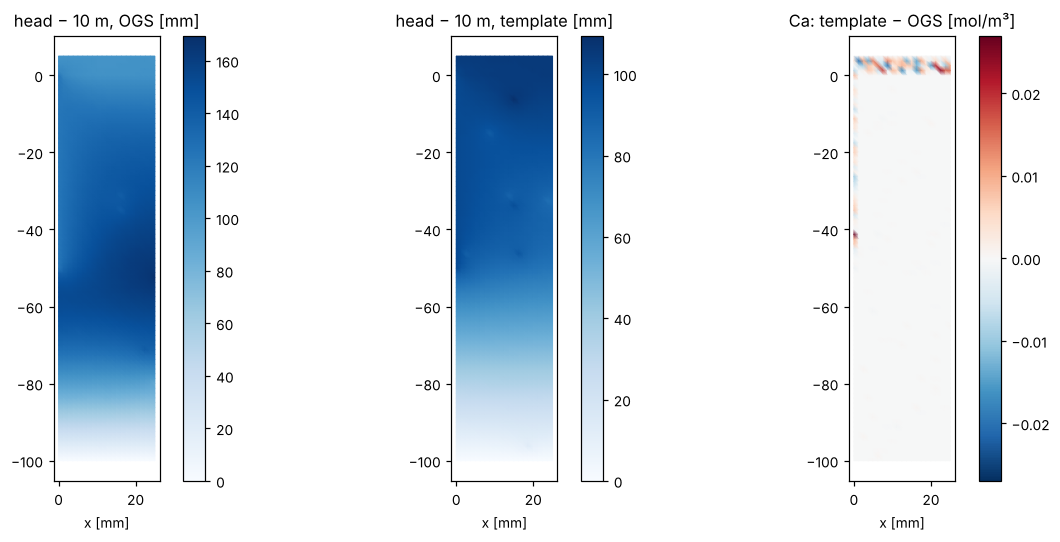

In [4]:
ref = np.load(CASE / 'reference' / 'ref_t10s.npz')
rows = []
for j, cn in enumerate(comps[:-2]):
    r_ = ref['node__' + cn]
    rows.append({'quantity': cn, **{n: np.abs(r['c'][:, j] - r_).max() / np.abs(r_).max() for n, r in runs.items()}})
for nm, key, rk in [('porosity', 'phi', 'NodePorosity'), ('pH', 'pH', 'Ph'), ('Portlandite', 'portlandite', 'Portlandite')]:
    r_ = ref['node__' + rk]
    rows.append({'quantity': nm, **{n: np.abs(r[key] - r_).max() / np.abs(r_).max() for n, r in runs.items()}})
r_ = ref['node__HEAD']
rows.append({'quantity': 'head − 10 m', **{n: np.abs(r['head'] - r_).max() / np.abs(r_ - 10).max() for n, r in runs.items()}})
display(pd.DataFrame(rows).set_index('quantity').style.format('{:.1e}').set_caption('max relative difference to OGS'))

main = runs['OGS FCT']
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
for a, (title, val, cmap) in zip(ax, [('head − 10 m, OGS [mm]', (ref['node__HEAD'] - 10) * 1e3, 'Blues'),
                                       ('head − 10 m, template [mm]', (main['head'] - 10) * 1e3, 'Blues'),
                                       ('Ca: template − OGS [mol/m³]', main['c'][:, 2] - ref['node__3-Ca'], 'RdBu_r')]):
    lim = np.abs(val).max() if 'Ca' in title else None
    m = a.tripcolor(tri, val, shading='gouraud', cmap=cmap, vmin=-lim if lim else None, vmax=lim)
    fig.colorbar(m, ax=a); a.set_title(title); a.set_aspect('equal'); a.set_xlabel('x [mm]')
plt.tight_layout(); plt.show()

浓度、孔隙率、pH 和 portlandite 一致到 GEMS 自身离散的水平（OGS 自己的结果里，成分完全相同的节点之间也差约 10⁻³）。
**水头对不上**，哪个变体都一样。下一个单元格说明原因。

## 为什么水头无法复现

水流矩阵把 $K = 0.41$ m/s 的裂缝和 $K = 5\times10^{-11}$ m/s 的混凝土耦合在一起——差十个数量级。
下面把*同一个矩阵*解两次，一次按 OGS 节点顺序，一次按 dolfinx 顺序：

In [5]:
import scipy.sparse.linalg as spla
from dolfinx import fem
flow = Darcy(mesh, fixed_nodes=np.r_[upper, lower], quadrature_degree=5)
flow.K_cell = harmonic_mean(kozeny_carman_4(k0_mat[mat][:, None], state0['phi0'][mesh.cells], state0['phi'][mesh.cells]))
mesh.set_cells(flow._K, flow.K_cell)
lc = crack.lines
A_dof = fem.assemble_matrix(flow._form).to_scipy().tocsr()
A_ogs = A_dof[mesh.node2dof][:, mesh.node2dof] + crack.flow_matrix(harmonic_mean(kozeny_carman_4(0.41, state0['phi0'][lc], state0['phi'][lc])))
A_dof = A_ogs[mesh.dof2node][:, mesh.dof2node]
fixed = np.r_[upper, lower]
hb = np.r_[np.full(len(upper), heads['UPPER_BOUNDARY']), np.full(len(lower), heads['LOWER_BOUNDARY'])]
def solve(A, fixed, hb):
    free = np.setdiff1d(np.arange(A.shape[0]), fixed)
    h = np.zeros(A.shape[0]); h[fixed] = hb
    h[free] = spla.spsolve(A[free][:, free].tocsc(), -A[free][:, fixed] @ hb)
    return h
h1 = solve(A_ogs, fixed, hb)
h2 = solve(A_dof, mesh.node2dof[fixed], hb)[mesh.node2dof]
print(f'same matrix, two orderings: max head difference {np.abs(h1 - h2).max():.1e} m '
      f'(head range {np.ptp(h1) * 1e3:.0f} mm, conductivity contrast {0.41 / 5e-11:.0e})')
concrete = (xz[:, 1] < -0.051) & (xz[:, 0] > 0.003)
print(f'excess water V_aq - phi after the last step: concrete median {np.median(np.abs(main["excess"][concrete])):.0e}, '
      f'whole domain max {np.abs(main["excess"]).max():.0e} m³ per m³')

same matrix, two orderings: max head difference 6.7e-06 m (head range 105 mm, conductivity contrast 8e+09)
excess water V_aq - phi after the last step: concrete median 4e-10, whole domain max 2e-06 m³ per m³


## 复现时遇到的坑

1. **vtk 的点比网格多。** `decal0010.vtk` 由 4 个 PETSc 进程依次写出，含 ghost 节点（1785 个节点写了 1915 个点）。要按坐标映射；
   里面的 `NodeVolume` 字段是 GEMS 的体系体积，*不是*源项用的节点体积。
2. **裂缝单元**的每个积分（质量、扩散、对流、水流）都乘 `GEOMETRY_AREA`。模板里它们就是加到全局矩阵上的 2×2 单元矩阵。
3. **φ ≈ 1 时的 Kozeny–Carman。** 裂缝孔隙率是 0.9999989（只有微量惰性固相），所以 $(1-\phi_0)/(1-\phi)$ 是两个 10⁻⁶ 量级的数相除。
   孔隙率一点点变化，裂缝 K 就从 0.41 变成 0.4655 m/s——OGS 也是这样。
4. **FCT 的符号。** OGS 在第 $j$ 行加 $+f_{ij}$。和这个参考比，OGS 符号和教科书符号分辨不出来：它们的差别比水头舍入误差的影响还小。
5. **水头。** 多余水 $V_{aq}-\phi$ 是 GEMS 的舍入误差（$10^{-10}$–$10^{-7}$），但在 $K = 5\times10^{-11}$ m/s 的混凝土里能把水头抬高几厘米。
   不同的 GEMS 版本噪声不同，病态的水流矩阵本身还带来约 10⁻⁵ m 的误差——这里逐节点比较水头没有意义。

## 练习

1. 算 1000 步 × 1 s（或 100 步 × 100 s）。溶蚀先从哪里开始，沿裂缝还是在表面？
2. 把裂缝“封上”：线单元用混凝土的渗透系数。水头和 N 的侵入深度怎么变？
3. 在 `Darcy` 求解前先按行缩放矩阵（Jacobi）。水头对节点顺序的依赖变小了吗？